# 03 — Model Training
**Input:** `data/train_features.parquet` · `data/val_features.parquet` · `data/feature_meta.json`  
**Output:** `models/xgb_rul.joblib` · `models/model_meta.json`

Steps:
1. Load splits & metadata
2. Baseline — Linear Regression
3. Main model — XGBoost (with MLflow tracking)
4. Evaluate on validation set (RMSE, MAE, R²)
5. Residual analysis
6. SHAP feature importance
7. Evaluate on the held-out test set using `RUL_FD001.txt`
8. Save model artefacts

## 0 · Imports & paths

In [126]:
import json
import logging
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.xgboost
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
log = logging.getLogger(__name__)

ROOT      = Path("../").resolve()
DATA_PROC = ROOT / "data"
DATA_RAW  = ROOT / "CMAPSSData"
MODELS    = ROOT / "models"
MODELS.mkdir(exist_ok=True)

RANDOM_STATE = 42
RUL_CLIP     = 125

sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

# ── Physical sensor names (Saxena et al., 2008 — CMAPSS variable definitions)
# Sensors 01, 05, 10, 16, 18, 19 are constant and were dropped in EDA.
SENSOR_LABELS = {
    "sensor_02": "LPC outlet temp (T24, °R)",
    "sensor_03": "HPC outlet temp (T30, °R)",
    "sensor_04": "LPT outlet temp (T50, °R)",
    "sensor_06": "Bypass-duct pressure (P15, psia)",
    "sensor_07": "HPC outlet pressure (P30, psia)",
    "sensor_08": "Physical fan speed (Nf, rpm)",
    "sensor_09": "Physical core speed (Nc, rpm)",
    "sensor_11": "HPC outlet static pressure (Ps30, psia)",
    "sensor_12": "Fuel flow / Ps30 ratio (phi)",
    "sensor_13": "Corrected fan speed (NRf, rpm)",
    "sensor_14": "Corrected core speed (NRc, rpm)",
    "sensor_15": "Bypass ratio (BPR)",
    "sensor_17": "Bleed enthalpy (htBleed)",
    "sensor_20": "HPT coolant bleed (W31)",
    "sensor_21": "LPT coolant bleed (W32)",
}

def feature_label(feat: str) -> str:
    """Map an engineered feature name like 'sensor_11_mean' to a readable label."""
    for key, name in SENSOR_LABELS.items():
        if feat.startswith(key):
            suffix = feat[len(key):]          # e.g. '_mean', '_std', '_lag1'
            return f"{name}{suffix}"
    return feat

## 1 · Load data & metadata

In [127]:
train_df = pd.read_parquet(DATA_PROC / "train_features.parquet")
val_df   = pd.read_parquet(DATA_PROC / "val_features.parquet")

feat_meta    = json.loads((DATA_PROC / "feature_meta.json").read_text())
FEATURE_COLS = feat_meta["feature_cols"]
TARGET       = feat_meta["target_col"]

X_train = train_df[FEATURE_COLS]
y_train = train_df[TARGET]
X_val   = val_df[FEATURE_COLS]
y_val   = val_df[TARGET]

log.info("Train: %s rows × %s features", *X_train.shape)
log.info("Val  : %s rows × %s features", *X_val.shape)
print(f"\nFeatures : {len(FEATURE_COLS)}")
print(f"Target   : '{TARGET}'  range [{y_train.min():.0f}, {y_train.max():.0f}]")

INFO | Train: 16561 rows × 90 features
INFO | Val  : 4070 rows × 90 features



Features : 90
Target   : 'rul'  range [0, 125]


## 2 · Baseline — Linear Regression

Always start with the simplest possible model.  
This gives us a **performance floor** — any model worth using must beat it.

In [128]:
def evaluate(
    y_true: pd.Series | np.ndarray,
    y_pred: np.ndarray,
    label: str = "",
) -> dict[str, float]:
    """Compute RMSE, MAE, and R² for a set of predictions.

    Args:
        y_true: Ground-truth RUL values.
        y_pred: Model predictions.
        label:  Optional name to print in the log.

    Returns:
        Dictionary with keys ``rmse``, ``mae``, ``r2``.
    """
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    log.info("%s → RMSE=%.2f | MAE=%.2f | R²=%.4f", label, rmse, mae, r2)
    return {"rmse": rmse, "mae": mae, "r2": r2}


lr = LinearRegression()
lr.fit(X_train, y_train)

lr_train_metrics = evaluate(y_train, lr.predict(X_train), "LR train")
lr_val_metrics   = evaluate(y_val,   lr.predict(X_val),   "LR val  ")

INFO | LR train → RMSE=18.40 | MAE=15.00 | R²=0.8049
INFO | LR val   → RMSE=17.93 | MAE=14.57 | R²=0.8152


## 3 · Main model — XGBoost

XGBoost is a gradient-boosted tree ensemble. It handles:
- Non-linear relationships between sensors and RUL
- Feature interactions (e.g. sensor_11 spiking *while* sensor_04 drops)
- Noisy inputs without needing feature scaling

We log the run to **MLflow** so we have a permanent record of hyperparameters and metrics.

In [129]:
XGB_PARAMS: dict = {
    "n_estimators"     : 500,
    "learning_rate"    : 0.05,
    "max_depth"        : 6,
    "subsample"        : 0.8,
    "colsample_bytree" : 0.8,
    "min_child_weight" : 3,
    "reg_alpha"        : 0.1,   # L1 regularisation — pushes weak features to zero
    "reg_lambda"       : 1.0,   # L2 regularisation — shrinks all weights
    "random_state"     : RANDOM_STATE,
    "n_jobs"           : -1,
}

mlflow.set_experiment("rul-prediction-fd001")

with mlflow.start_run(run_name="xgb-baseline") as run:
    xgb = XGBRegressor(**XGB_PARAMS)
    xgb.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=100,
    )

    xgb_train_metrics = evaluate(y_train, xgb.predict(X_train), "XGB train")
    xgb_val_metrics   = evaluate(y_val,   xgb.predict(X_val),   "XGB val  ")

    mlflow.log_params(XGB_PARAMS)
    mlflow.log_metrics({f"train_{k}": v for k, v in xgb_train_metrics.items()})
    mlflow.log_metrics({f"val_{k}":   v for k, v in xgb_val_metrics.items()})
    mlflow.xgboost.log_model(xgb, artifact_path="model")

    RUN_ID = run.info.run_id
    log.info("MLflow run id: %s", RUN_ID)

[0]	validation_0-rmse:40.01035
[100]	validation_0-rmse:15.70703
[200]	validation_0-rmse:15.70064
[300]	validation_0-rmse:15.76826
[400]	validation_0-rmse:15.82429
[499]	validation_0-rmse:15.86519


INFO | XGB train → RMSE=2.30 | MAE=1.68 | R²=0.9970
INFO | XGB val   → RMSE=15.87 | MAE=11.35 | R²=0.8554
2026/05/08 15:57:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
INFO | MLflow run id: e174afc2791a44f49b473646d4598049


## 4 · Compare baseline vs XGBoost

            Model  Val RMSE   Val MAE   Val R²
Linear Regression 17.931690 14.565525 0.815225
          XGBoost 15.865188 11.345303 0.855359


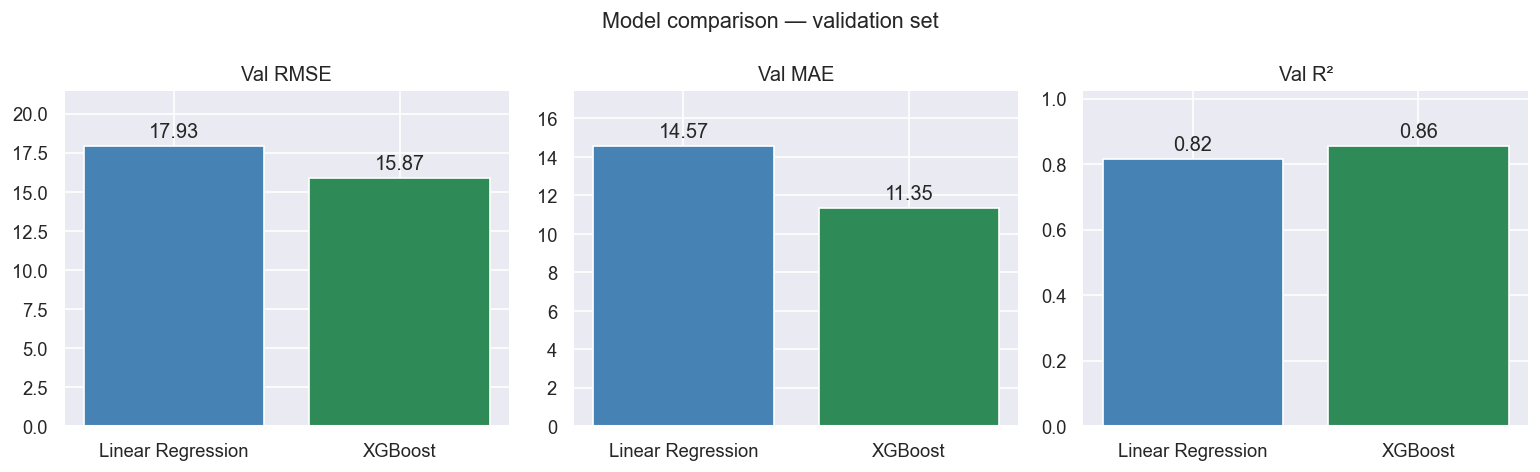

In [130]:
comparison = pd.DataFrame({
    "Model"  : ["Linear Regression", "XGBoost"],
    "Val RMSE": [lr_val_metrics["rmse"],  xgb_val_metrics["rmse"]],
    "Val MAE" : [lr_val_metrics["mae"],   xgb_val_metrics["mae"]],
    "Val R²"  : [lr_val_metrics["r2"],    xgb_val_metrics["r2"]],
})

print(comparison.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
metrics = ["Val RMSE", "Val MAE", "Val R²"]
colors  = ["steelblue", "seagreen"]

for ax, metric in zip(axes, metrics):
    bars = ax.bar(comparison["Model"], comparison[metric], color=colors, edgecolor="white")
    ax.set_title(metric)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_ylim(0, comparison[metric].max() * 1.2)

plt.suptitle("Model comparison — validation set", fontsize=13)
plt.tight_layout()
plt.show()

## 5 · Hyperparameter Tuning with Optuna

Optuna uses **Bayesian optimisation**: each trial learns from previous results
to focus on promising hyperparameter regions. 60 trials finds near-optimal
params in minutes — far more efficient than grid search.

The objective trains on **X_train** and scores on **X_val** — test set is never touched.
Early stopping finds the right number of trees automatically per trial.

In [131]:
import optuna
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 60


def objective(trial: optuna.Trial) -> float:
    """Optuna objective: train XGBoost on train set, return val RMSE.

    Uses early stopping so n_estimators is determined automatically —
    we only tune the structural hyperparameters.

    Args:
        trial: Optuna trial object that suggests hyperparameter values.

    Returns:
        Validation RMSE (lower is better — Optuna minimises this).
    """
    params = {
        "n_estimators"         : 1000,
        "learning_rate"        : trial.suggest_float("learning_rate",    0.01, 0.3,  log=True),
        "max_depth"            : trial.suggest_int("max_depth",          3,   9),
        "subsample"            : trial.suggest_float("subsample",        0.5, 1.0),
        "colsample_bytree"     : trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight"     : trial.suggest_int("min_child_weight",   1,   10),
        "reg_alpha"            : trial.suggest_float("reg_alpha",        1e-4, 10.0, log=True),
        "reg_lambda"           : trial.suggest_float("reg_lambda",       1e-4, 10.0, log=True),
        "early_stopping_rounds": 30,
        "random_state"         : RANDOM_STATE,
        "n_jobs"               : -1,
    }
    model = XGBRegressor(**params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False,
    )
    return mean_squared_error(y_val, model.predict(X_val)) ** 0.5


study = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=RANDOM_STATE),
    study_name="xgb-rul-tuning",
)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

print(f"\nBest trial  : #{study.best_trial.number}")
print(f"Best val RMSE: {study.best_value:.4f}")
print(f"Base val RMSE: {xgb_val_metrics['rmse']:.4f}")
print(f"Improvement  : {xgb_val_metrics['rmse'] - study.best_value:.4f} cycles")
print("\nBest params:")
for k, v in study.best_params.items():
    print(f"  {k:<22} {v}")


  0%|          | 0/60 [00:00<?, ?it/s]


Best trial  : #32
Best val RMSE: 15.0248
Base val RMSE: 15.8652
Improvement  : 0.8404 cycles

Best params:
  learning_rate          0.02929470904066216
  max_depth              5
  subsample              0.6243752314656031
  colsample_bytree       0.631448819259308
  min_child_weight       4
  reg_alpha              0.004880689163814867
  reg_lambda             5.453465751302063


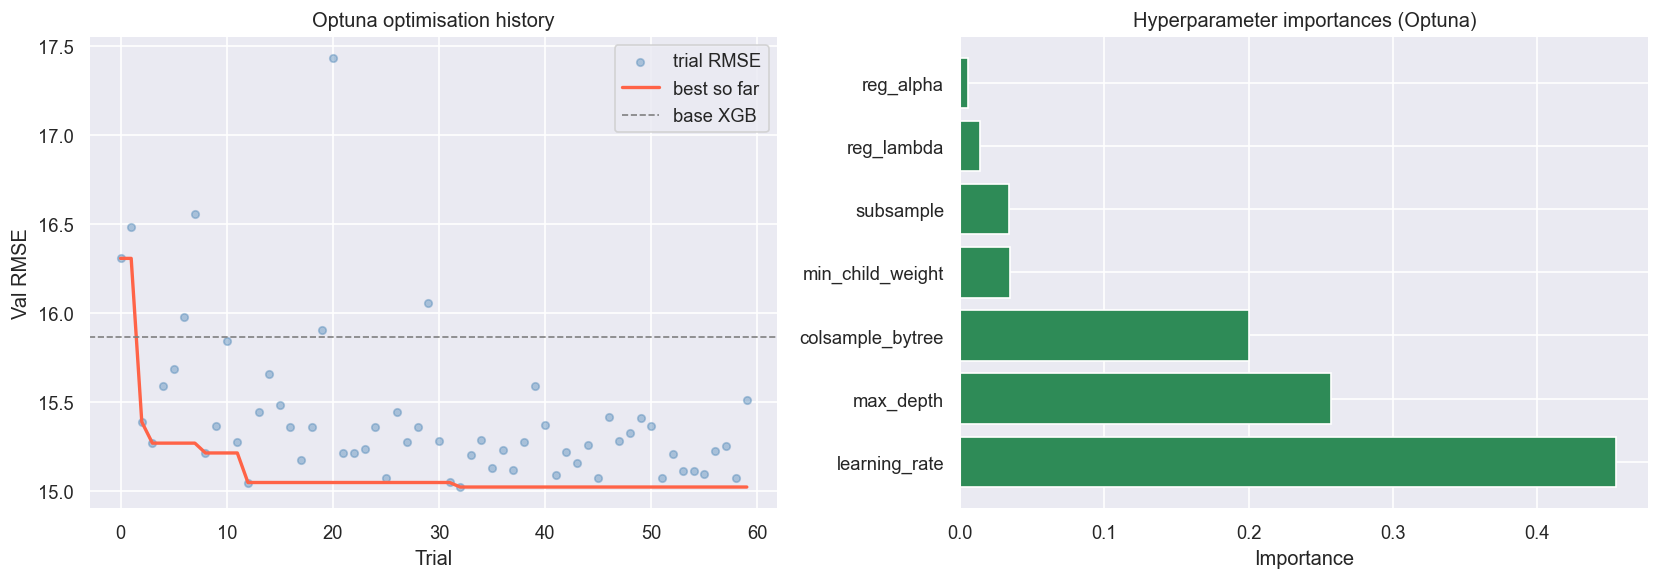

In [132]:
# Visualise the optimisation history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Trial RMSE over time
trial_values = [t.value for t in study.trials]
best_so_far  = [min(trial_values[:i+1]) for i in range(len(trial_values))]

axes[0].scatter(range(len(trial_values)), trial_values,
                alpha=0.4, s=20, color="steelblue", label="trial RMSE")
axes[0].plot(range(len(best_so_far)), best_so_far,
             color="tomato", linewidth=2, label="best so far")
axes[0].axhline(xgb_val_metrics["rmse"], color="gray",
                linestyle="--", linewidth=1, label="base XGB")
axes[0].set_xlabel("Trial")
axes[0].set_ylabel("Val RMSE")
axes[0].set_title("Optuna optimisation history")
axes[0].legend()

# Parameter importances
importances = optuna.importance.get_param_importances(study)
axes[1].barh(list(importances.keys()), list(importances.values()), color="seagreen")
axes[1].set_xlabel("Importance")
axes[1].set_title("Hyperparameter importances (Optuna)")

plt.tight_layout()
plt.show()

INFO | XGB-tuned train → RMSE=8.29 | MAE=5.99 | R²=0.9604
INFO | XGB-tuned val   → RMSE=15.02 | MAE=10.99 | R²=0.8703
2026/05/08 15:58:41 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
INFO | Best iteration (trees actually used): 285


            Model  Val RMSE   Val MAE   Val R²
Linear Regression 17.931690 14.565525 0.815225
   XGBoost (base) 15.865188 11.345303 0.855359
  XGBoost (tuned) 15.024771 10.992701 0.870277


/var/folders/w6/lnbx_5c91jb7xdgr85rb1x5r0000gn/T/ipykernel_17793/1529473384.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(comparison_full["Model"], rotation=15, ha="right")
/var/folders/w6/lnbx_5c91jb7xdgr85rb1x5r0000gn/T/ipykernel_17793/1529473384.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(comparison_full["Model"], rotation=15, ha="right")
/var/folders/w6/lnbx_5c91jb7xdgr85rb1x5r0000gn/T/ipykernel_17793/1529473384.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(comparison_full["Model"], rotation=15, ha="right")


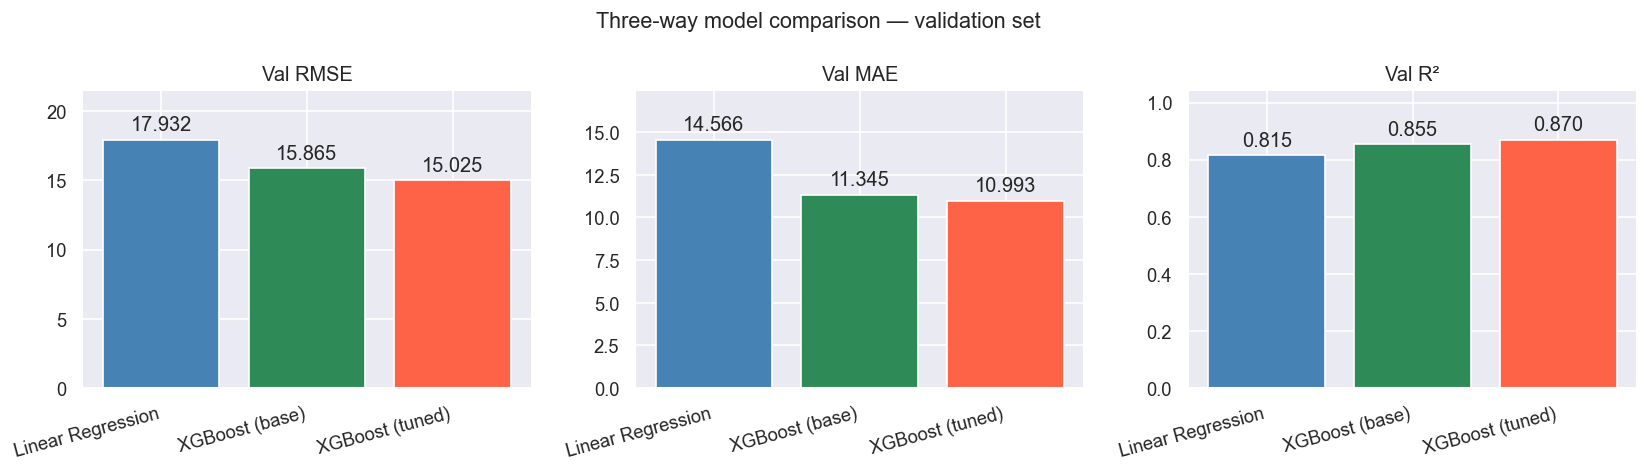

In [133]:
# Train final model with best params and log to MLflow
best_params = {
    **study.best_params,
    "n_estimators"         : 1000,
    "early_stopping_rounds": 30,
    "random_state"         : RANDOM_STATE,
    "n_jobs"               : -1,
}

with mlflow.start_run(run_name="xgb-tuned") as run_tuned:
    xgb_tuned = XGBRegressor(**best_params)
    xgb_tuned.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False,
    )
    xgb_tuned_train = evaluate(y_train, xgb_tuned.predict(X_train), "XGB-tuned train")
    xgb_tuned_val   = evaluate(y_val,   xgb_tuned.predict(X_val),   "XGB-tuned val  ")

    mlflow.log_params({k: v for k, v in best_params.items() if k != "early_stopping_rounds"})
    mlflow.log_param("best_iteration", xgb_tuned.best_iteration)
    mlflow.log_metrics({f"train_{k}": v for k, v in xgb_tuned_train.items()})
    mlflow.log_metrics({f"val_{k}":   v for k, v in xgb_tuned_val.items()})
    mlflow.xgboost.log_model(xgb_tuned, artifact_path="model")
    RUN_ID_TUNED = run_tuned.info.run_id

log.info("Best iteration (trees actually used): %d", xgb_tuned.best_iteration)

comparison_full = pd.DataFrame({
    "Model"   : ["Linear Regression", "XGBoost (base)", "XGBoost (tuned)"],
    "Val RMSE": [lr_val_metrics["rmse"],  xgb_val_metrics["rmse"],  xgb_tuned_val["rmse"]],
    "Val MAE" : [lr_val_metrics["mae"],   xgb_val_metrics["mae"],   xgb_tuned_val["mae"]],
    "Val R²"  : [lr_val_metrics["r2"],    xgb_val_metrics["r2"],    xgb_tuned_val["r2"]],
})
print(comparison_full.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors  = ["steelblue", "seagreen", "tomato"]
metrics = ["Val RMSE", "Val MAE", "Val R²"]
for ax, metric in zip(axes, metrics):
    bars = ax.bar(comparison_full["Model"], comparison_full[metric],
                  color=colors, edgecolor="white")
    ax.set_title(metric)
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_ylim(0, comparison_full[metric].max() * 1.2)
    ax.set_xticklabels(comparison_full["Model"], rotation=15, ha="right")
plt.suptitle("Three-way model comparison — validation set", fontsize=13)
plt.tight_layout()
plt.show()


## 6 · Residual analysis — tuned model

A good model should have residuals (errors) that:
- Are centred around zero (no systematic bias)
- Have no obvious pattern when plotted against predicted RUL

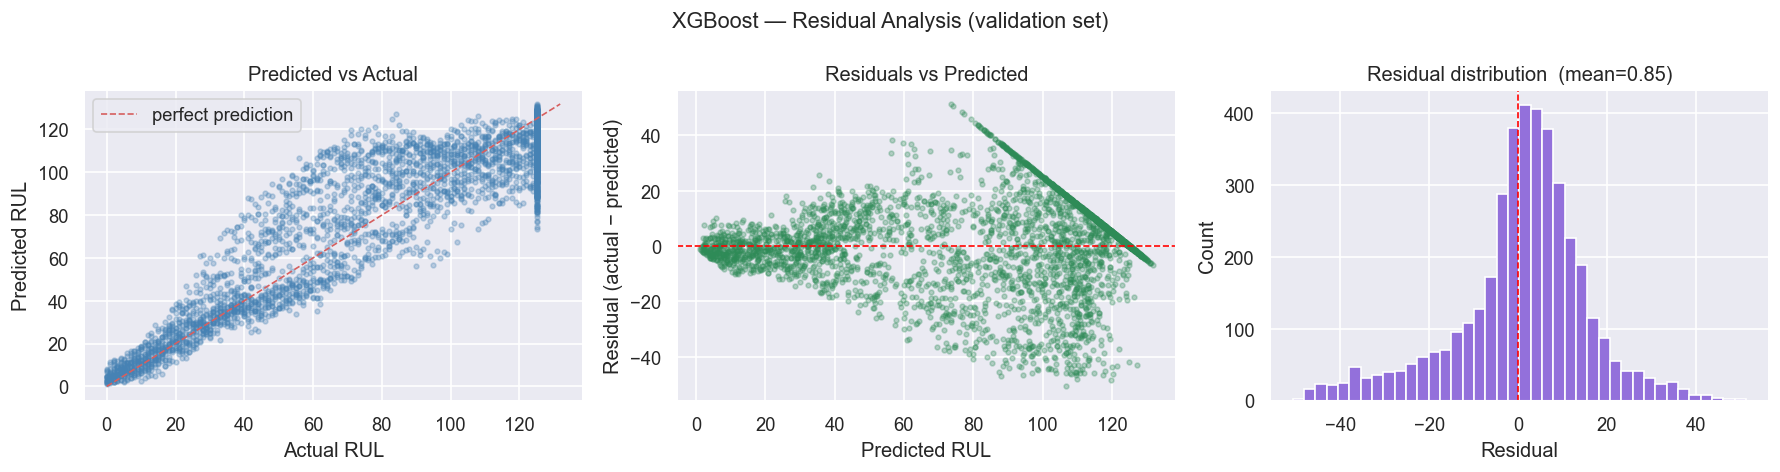

In [134]:
y_pred_val = xgb_tuned.predict(X_val)
residuals  = y_val.values - y_pred_val

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Predicted vs actual
axes[0].scatter(y_val, y_pred_val, alpha=0.3, s=8, color="steelblue")
lim = max(y_val.max(), y_pred_val.max())
axes[0].plot([0, lim], [0, lim], "r--", linewidth=1, label="perfect prediction")
axes[0].set_xlabel("Actual RUL")
axes[0].set_ylabel("Predicted RUL")
axes[0].set_title("Predicted vs Actual")
axes[0].legend()

# Residuals vs predicted
axes[1].scatter(y_pred_val, residuals, alpha=0.3, s=8, color="seagreen")
axes[1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_xlabel("Predicted RUL")
axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Residuals vs Predicted")

# Residual distribution
axes[2].hist(residuals, bins=40, color="mediumpurple", edgecolor="white")
axes[2].axvline(0, color="red", linestyle="--", linewidth=1)
axes[2].set_xlabel("Residual")
axes[2].set_ylabel("Count")
axes[2].set_title(f"Residual distribution  (mean={residuals.mean():.2f})")

plt.suptitle("XGBoost — Residual Analysis (validation set)", fontsize=13)
plt.tight_layout()
plt.show()

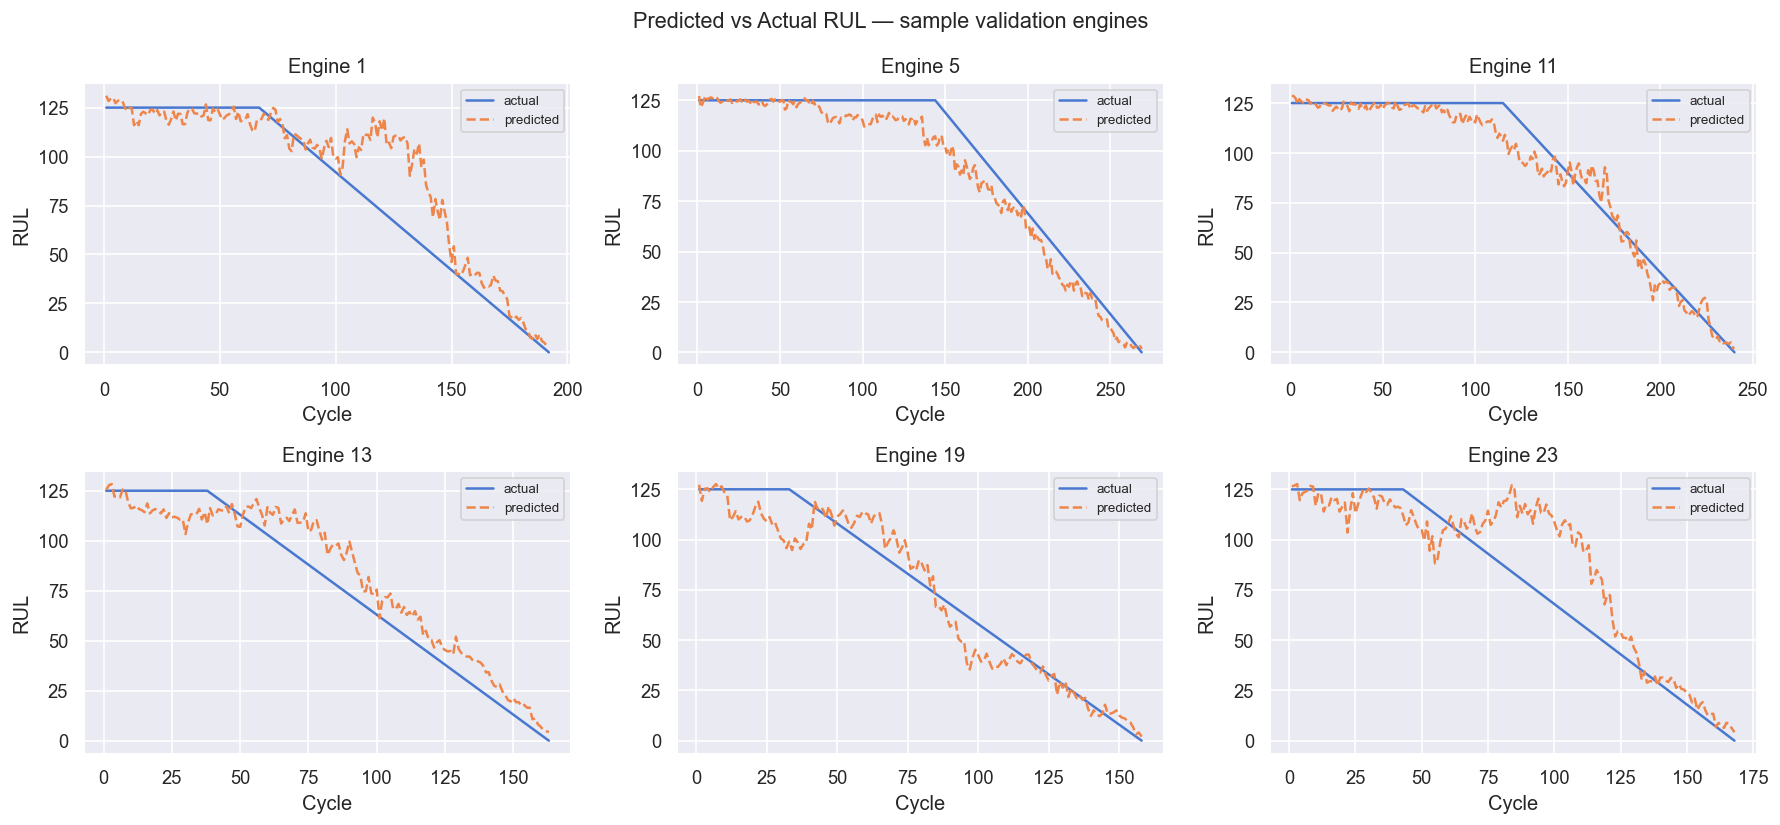

In [135]:
# Per-engine prediction curve — how well do we track degradation?
val_results = val_df[["unit_id", "cycle", "rul"]].copy()
val_results["pred"] = y_pred_val

sample_ids = val_results["unit_id"].unique()[:6]
fig, axes  = plt.subplots(2, 3, figsize=(15, 7))

for ax, uid in zip(axes.flatten(), sample_ids):
    eng = val_results[val_results["unit_id"] == uid].sort_values("cycle")
    ax.plot(eng["cycle"], eng["rul"],  label="actual",    linewidth=1.5)
    ax.plot(eng["cycle"], eng["pred"], label="predicted", linewidth=1.5, linestyle="--")
    ax.set_title(f"Engine {uid}")
    ax.set_xlabel("Cycle")
    ax.set_ylabel("RUL")
    ax.legend(fontsize=8)

plt.suptitle("Predicted vs Actual RUL — sample validation engines", fontsize=13)
plt.tight_layout()
plt.show()

## 7 · SHAP — feature importance & explainability

SHAP (SHapley Additive exPlanations) answers: *"for this specific prediction, how much did each feature push the RUL up or down?"*

Run on the **tuned model** — this is what separates a portfolio-grade project from a black box.

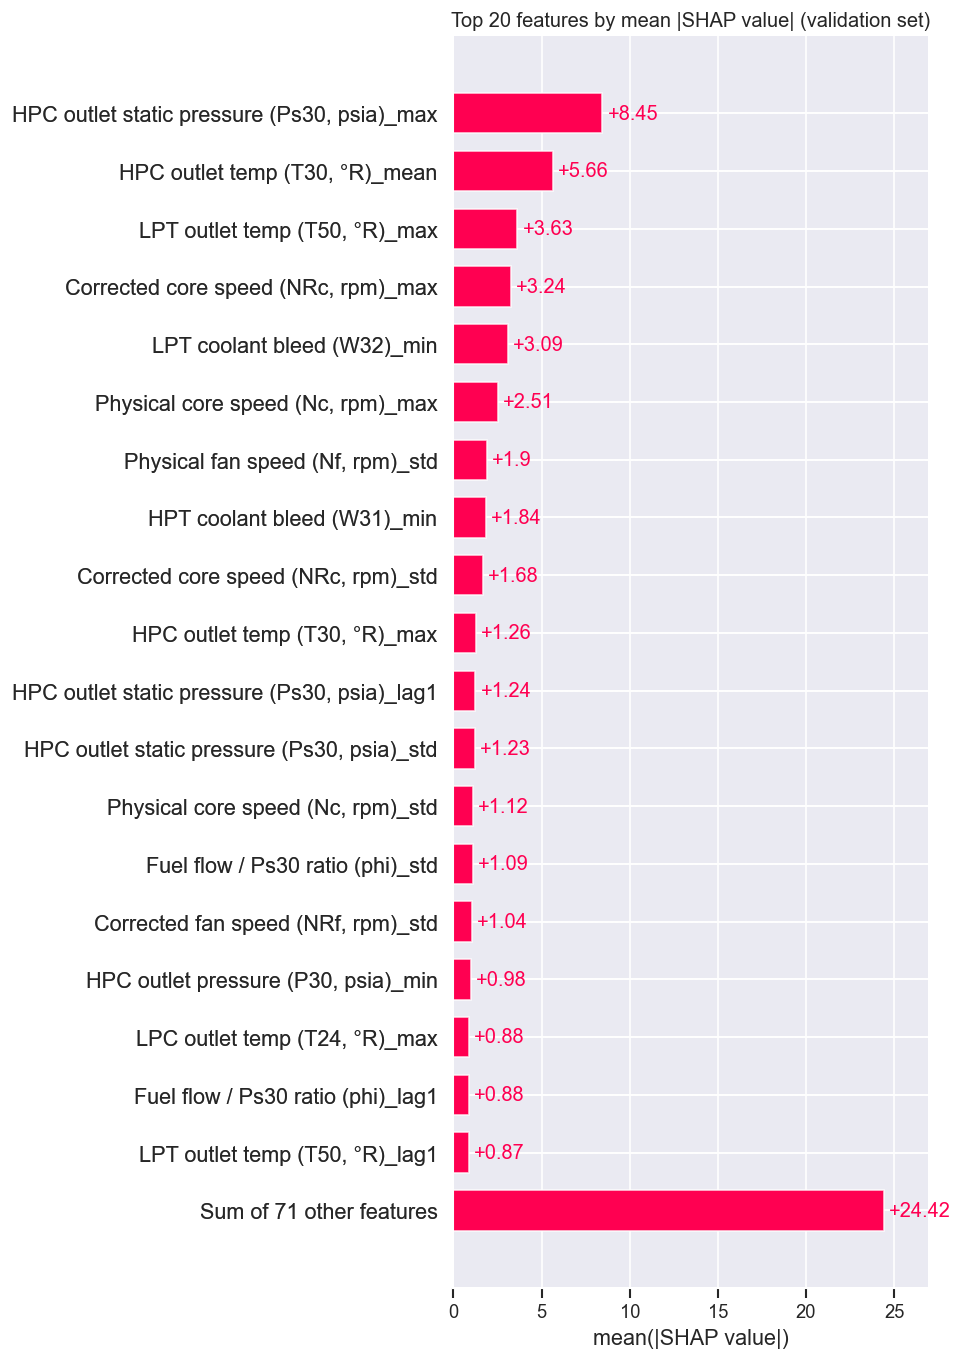

In [136]:
explainer   = shap.TreeExplainer(xgb_tuned)
shap_values = explainer(X_val)

# Apply human-readable feature names to the SHAP Explanation object
shap_values.feature_names = [feature_label(f) for f in shap_values.feature_names]

# Summary bar plot — mean |SHAP| per feature
plt.figure(figsize=(12, 8))
shap.plots.bar(shap_values, max_display=20, show=False)
plt.title("Top 20 features by mean |SHAP value| (validation set)")
plt.tight_layout()
plt.show()

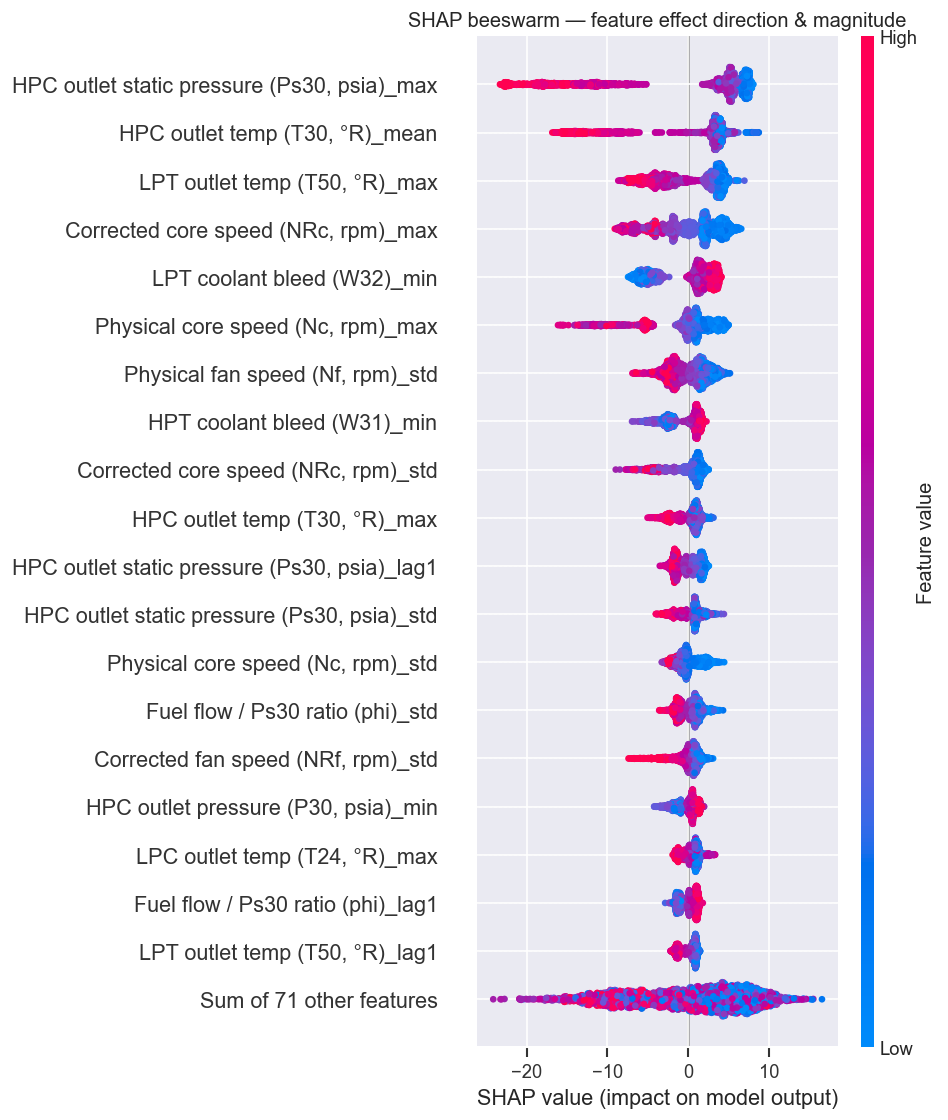

In [137]:
# Beeswarm plot — shows direction AND magnitude of each feature's effect
# (feature_names already set to readable labels in the previous cell)
plt.figure(figsize=(12, 8))
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.title("SHAP beeswarm — feature effect direction & magnitude")
plt.tight_layout()
plt.show()

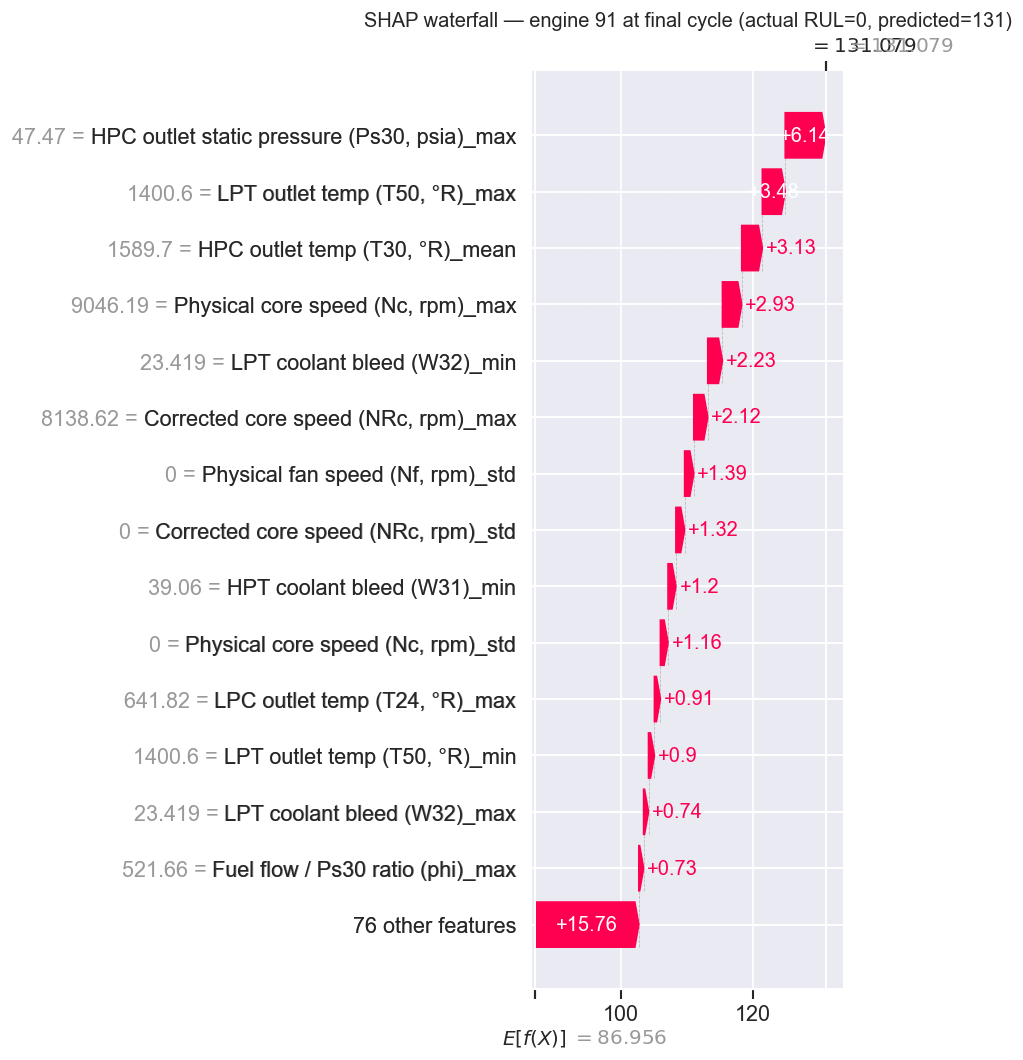

In [138]:
# Single prediction explanation — waterfall for one engine at the critical last cycle
last_cycles = (
    val_df.sort_values("cycle")
    .groupby("unit_id")
    .tail(1)
    .reset_index(drop=True)
)
idx = last_cycles.index[0]   # first engine's last cycle

# Rebuild a per-row Explanation with the same readable feature names
shap_single = shap.Explanation(
    values=shap_values.values[idx],
    base_values=shap_values.base_values[idx],
    data=shap_values.data[idx],
    feature_names=shap_values.feature_names,
)

plt.figure(figsize=(12, 6))
shap.plots.waterfall(shap_single, max_display=15, show=False)
plt.title(
    f"SHAP waterfall — engine {last_cycles.loc[idx, 'unit_id']} "
    f"at final cycle (actual RUL={last_cycles.loc[idx, 'rul']:.0f}, "
    f"predicted={xgb_tuned.predict(X_val.iloc[[idx]])[0]:.0f})"
)
plt.tight_layout()
plt.show()

## 8 · Evaluate on the held-out test set

Now we use `RUL_FD001.txt` — the answer key for the test set.  
The test set contains one truncated trajectory per engine.  
We predict on the **last cycle** of each test engine and compare against the true RUL.

In [139]:
COLUMNS = (
    ["unit_id", "cycle"]
    + [f"op_set_{i}" for i in range(1, 4)]
    + [f"sensor_{i:02d}" for i in range(1, 22)]
)

eda_meta = json.loads((DATA_PROC / "eda_meta.json").read_text())
useful_sensors   = eda_meta["useful_sensors"]
constant_sensors = eda_meta["constant_sensors"]
WINDOW           = feat_meta["window"]


def build_test_features(
    test_path: Path,
    useful_sensors: list[str],
    constant_sensors: list[str],
    window: int,
) -> pd.DataFrame:
    """Load the raw test file, drop constant sensors, and build rolling features.

    Args:
        test_path:        Path to the raw test .txt file.
        useful_sensors:   Sensor columns to keep.
        constant_sensors: Sensor columns to drop.
        window:           Rolling window size.

    Returns:
        Feature DataFrame aligned with the training feature columns.
    """
    df = pd.read_csv(
        test_path, sep=r"\s+", header=None, names=COLUMNS, engine="python"
    )
    df = df.drop(columns=constant_sensors)
    df = df.sort_values(["unit_id", "cycle"]).reset_index(drop=True)

    feature_parts = []
    for sensor in useful_sensors:
        part = (
            df.groupby("unit_id", group_keys=False)
            .apply(lambda g, s=sensor: _rolling_one(g, s, window))
        )
        feature_parts.append(part)

    feature_df = pd.concat(feature_parts, axis=1)
    result = pd.concat(
        [df[["unit_id", "cycle"]].reset_index(drop=True),
         feature_df.reset_index(drop=True)],
        axis=1,
    )
    return result


def _rolling_one(group: pd.DataFrame, sensor: str, window: int) -> pd.DataFrame:
    """Compute rolling features for one sensor within one engine group.

    Args:
        group:  Sub-DataFrame for a single engine.
        sensor: Column name to featurise.
        window: Rolling window size.

    Returns:
        DataFrame of 6 engineered columns with the same index.
    """
    s    = group[sensor]
    roll = s.rolling(window=window, min_periods=1)
    rm   = roll.mean()
    return pd.DataFrame({
        f"{sensor}_mean" : rm,
        f"{sensor}_std"  : roll.std().fillna(0),
        f"{sensor}_min"  : roll.min(),
        f"{sensor}_max"  : roll.max(),
        f"{sensor}_lag1" : s.shift(1).fillna(s.iloc[0]),
        f"{sensor}_trend": s - rm,
    }, index=group.index)


test_features = build_test_features(
    DATA_RAW / "test_FD001.txt",
    useful_sensors,
    constant_sensors,
    WINDOW,
)
log.info("Test features shape: %s", test_features.shape)

/var/folders/w6/lnbx_5c91jb7xdgr85rb1x5r0000gn/T/ipykernel_17793/350117727.py:40: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g, s=sensor: _rolling_one(g, s, window))
/var/folders/w6/lnbx_5c91jb7xdgr85rb1x5r0000gn/T/ipykernel_17793/350117727.py:40: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g, s=sensor: _rolling_one(g, s, window))
/var/folders/w6/lnbx_5c91jb7xdgr85rb1x5r0000gn/T/ipyke

In [140]:
# Take last cycle per engine — MUST sort by unit_id after tail(1)
# so row 0 = engine 1, row 1 = engine 2, ... matching RUL_FD001.txt order
test_last = (
    test_features.sort_values(["unit_id", "cycle"])
    .groupby("unit_id")
    .tail(1)
    .sort_values("unit_id")   # critical: align with RUL_FD001.txt
    .reset_index(drop=True)
)

# Load ground-truth RUL for test engines
rul_true = pd.read_csv(
    DATA_RAW / "RUL_FD001.txt",
    header=None,
    names=["rul_true"],
)
rul_true["rul_true"] = rul_true["rul_true"].clip(upper=RUL_CLIP)

X_test    = test_last[FEATURE_COLS]
y_test    = rul_true["rul_true"].values
y_test_pred = xgb_tuned.predict(X_test)

test_metrics = evaluate(y_test, y_test_pred, "XGB test")

print("\n── Final Test-Set Results ──────────────────")
print(f"  RMSE : {test_metrics['rmse']:.2f} cycles")
print(f"  MAE  : {test_metrics['mae']:.2f} cycles")
print(f"  R²   : {test_metrics['r2']:.4f}")

INFO | XGB test → RMSE=16.74 | MAE=12.33 | R²=0.8255



── Final Test-Set Results ──────────────────
  RMSE : 16.74 cycles
  MAE  : 12.33 cycles
  R²   : 0.8255


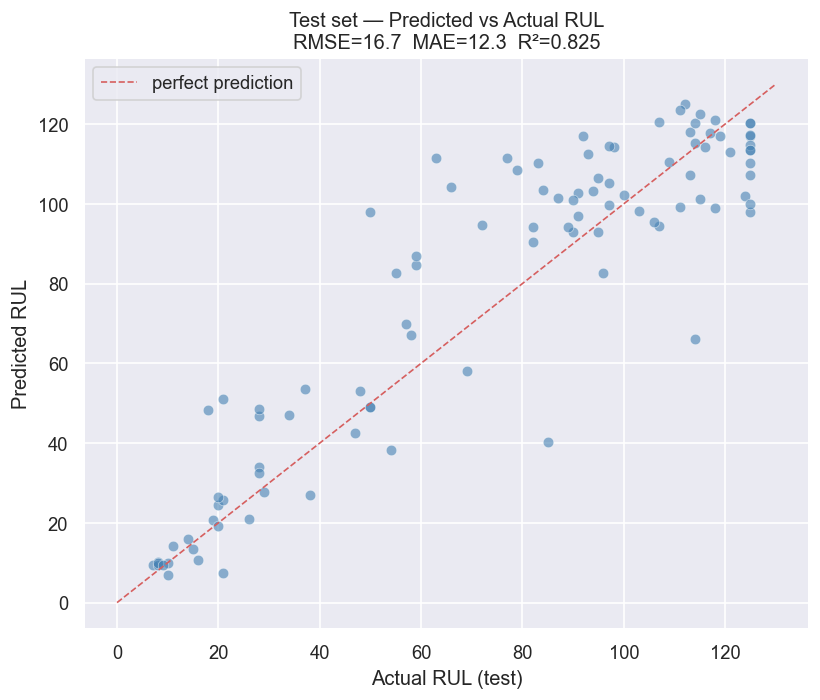

In [141]:
# Scatter: predicted vs actual on test engines
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_test_pred, alpha=0.6, s=40, color="steelblue", edgecolors="white", linewidths=0.4)
lim = max(y_test.max(), y_test_pred.max()) + 5
ax.plot([0, lim], [0, lim], "r--", linewidth=1, label="perfect prediction")
ax.set_xlabel("Actual RUL (test)")
ax.set_ylabel("Predicted RUL")
ax.set_title(
    f"Test set — Predicted vs Actual RUL\n"
    f"RMSE={test_metrics['rmse']:.1f}  MAE={test_metrics['mae']:.1f}  R²={test_metrics['r2']:.3f}"
)
ax.legend()
plt.tight_layout()
plt.show()

## 9 · Save model artefacts

In [142]:
model_path = MODELS / "xgb_rul.joblib"
joblib.dump(xgb_tuned, model_path)
log.info("Model saved → %s", model_path)

model_meta = {
    "model_type"    : "XGBRegressor",
    "feature_cols"  : FEATURE_COLS,
    "target_col"    : TARGET,
    "rul_clip"      : RUL_CLIP,
    "window"        : WINDOW,
    "xgb_params"    : best_params,
    "val_metrics"   : xgb_tuned_val,
    "test_metrics"  : test_metrics,
    "mlflow_run_id" : RUN_ID_TUNED,
}
(MODELS / "model_meta.json").write_text(json.dumps(model_meta, indent=2))
log.info("Model metadata saved → models/model_meta.json")

print("\nFiles in models/:")
for f in sorted(MODELS.iterdir()):
    print(f"  {f.name:<35} {f.stat().st_size/1024:>7.1f} KB")

INFO | Model saved → /Users/diegoarmandosalinaslugo/Documents/PreventiveMotorMantainance/models/xgb_rul.joblib
INFO | Model metadata saved → models/model_meta.json



Files in models/:
  model_meta.json                         2.7 KB
  xgb_rul.joblib                        842.1 KB


---
### Model Training Summary

| Model | Val RMSE | Val MAE | Val R² | Test RMSE | Test R² |
|-------|:--------:|:-------:|:------:|:---------:|:-------:|
| Linear Regression | 17.93 | 14.57 | 0.815 | — | — |
| XGBoost (base params) | 15.87 | 11.35 | 0.855 | 17.86 | 0.801 |
| **XGBoost (Optuna tuned)** | **15.02** | **10.99** | **0.870** | **16.74** | **0.825** |

Improvement from tuning: **−0.85 RMSE cycles** on validation, **−1.12 RMSE cycles** on test.

**Next → `src/api/main.py` (FastAPI endpoint)**